# Course-End Project: Agentic RAG — Router–Retriever with PDF and Web Search

**Dataset:** Uploaded 15-page *Attention Is All You Need* (Vaswani et al.).  
**Framework:** CrewAI | **PDF search:** `crewai_tools.PDFSearchTool` | **Vector DB:** ChromaDB | **Web search:** `langchain_tavily.TavilySearch`.  
**LLM:** Groq `openai/gpt-oss-120b` | **Embeddings:** local ONNX `all-MiniLM-L6-v2`.

**Run order:** install → load PDF & credentials → configure tools → define agents → run demo → inspect event trace. Live execution requires Groq and Tavily API keys plus internet. Sample outputs are *not* pre-generated or claimed to be live tests.

**Learning outcomes**
1. Classify a natural-language question with a Router Agent.
2. Allow the Retriever Agent to access **only the chosen tool** (PDF / Web / none).
3. Answer with PDF citation or web URLs, and report uncertainty when evidence is insufficient.
4. Log observable agent decisions, tool calls, outputs, and timings in JSONL; visualize the execution trace.

## 1. Architecture and routing rationale

```text
                        User question
                             |
                    [CrewAI Router Agent]
                             |
                     route + short reason
                       /     |      \
                    PDF     WEB    GENERAL
                     |       |        |
            PDFSearchTool  Tavily    no tool
                   \       |       /
                   [CrewAI Retriever Agent]
                             |
                    grounded answer
                             |
                 trace JSONL + timeline
```

**Why two CrewAI crew runs instead of one static sequential crew?** CrewAI's sequential process passes earlier task results to later tasks, but tool authorization is set at agent/task construction time. To enforce true routing, the system runs the Router task first, validates its typed decision, then dynamically creates the Retriever task with only the chosen tool. Both stages use CrewAI `Agent`, `Task`, `Crew`, and `Process.sequential`. This avoids exposing both tools to every query.

**Source policies:** PDF questions about the uploaded research paper use its vector index; current/latest/external questions use Tavily; simple general requests can use LLM-only generation. A factual PDF/web answer must use retrieved evidence, not internal model knowledge.

**Traceability:** the logs show observable decisions and interactions—not hidden private model chain-of-thought.

In [1]:
# 2. Install packages in this notebook's active Python environment.
# Run once, then restart kernel if the notebook prompts you to.
%pip install -q -U crewai[litellm] litellm==1.88.6 crewai-tools chromadb langchain-tavily tavily-python pypdf python-dotenv pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# 3. Import and verify prerequisites.
import os, json, re, time, uuid
from datetime import datetime, timezone
from pathlib import Path
from getpass import getpass
from typing import Literal

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from pydantic import BaseModel, Field
from pypdf import PdfReader
from crewai import Agent, Crew, Process, Task, LLM
from crewai.tools import tool
from crewai_tools import PDFSearchTool

# Put notebook and PDF in the same directory, OR adjust the path below.
PDF_CANDIDATES = [
    Path('trasformer_research_paper-dataset.pdf'),
    Path('data/trasformer_research_paper-dataset.pdf'),
    Path('/mnt/data/trasformer_research_paper-dataset.pdf'),
]
PDF_PATH = next((p.resolve() for p in PDF_CANDIDATES if p.is_file()), None)
if PDF_PATH is None:
    raise FileNotFoundError('Place trasformer_research_paper-dataset.pdf next to this notebook.')

reader = PdfReader(str(PDF_PATH))
assert len(reader.pages) >= 10, 'Unexpectedly short research paper.'
first_page = reader.pages[0].extract_text() or ''
assert 'Attention Is All You Need' in first_page, 'The PDF is not the expected paper.'
print(f'PDF loaded: {PDF_PATH.name} | {len(reader.pages)} pages')

PDF loaded: trasformer_research_paper-dataset.pdf | 15 pages


In [3]:
# 4. Credentials (not saved to the notebook or trace logs).
# Groq runs the chat model; PDF embeddings run locally with ONNX; Tavily provides live web search.
# Set these in your shell/.env ahead of time to skip interactive prompts.
from dotenv import load_dotenv
load_dotenv(override=False)

def ensure_key(name: str):
    if not os.getenv(name):
        value = getpass(f'Enter {name}: ').strip()
        if not value:
            raise ValueError(f'{name} is required to run the live demo.')
        os.environ[name] = value

ensure_key('GROQ_API_KEY')
ensure_key('TAVILY_API_KEY')
LLM_MODEL = os.getenv('CREWAI_LLM_MODEL', 'groq/openai/gpt-oss-120b')
from crewai.utilities.types import LLMMessage

class GroqCompatibleLLM(LLM):
    def _format_messages_for_provider(self, messages: list[LLMMessage]) -> list[dict[str, str]]:
        # Groq rejects CrewAI's internal prompt-cache marker; it is not user content.
        cleaned = [
            {key: value for key, value in message.items() if key != 'cache_breakpoint'}
            for message in messages
        ]
        return super()._format_messages_for_provider(cleaned)

llm = GroqCompatibleLLM(model=LLM_MODEL, temperature=0)
print('API keys present (values hidden); LLM:', LLM_MODEL)

API keys present (values hidden); LLM: groq/openai/gpt-oss-120b


## 5. Retrieval backends

`PDFSearchTool` automatically chunks/indexes the PDF and retrieves semantically related content. Its embeddings are stored in **ChromaDB**. Live web search uses the maintained `langchain_tavily.TavilySearch` integration. Search result URLs are preserved for citation.

    > PDF embeddings run locally with ChromaDB's ONNX MiniLM model, so no OpenAI key or embedding API calls are needed. The model may be downloaded on first use. Web queries require Tavily API access. The PDF tool can return excerpts without reliable page metadata, so the agent cites the document title unless the retrieved text itself supplies verified page information.

In [4]:
# Instantiate search backends lazily: the PDF vector index is created only on first PDF question.
_PDF_BACKEND = None
_WEB_BACKEND = None

def get_pdf_backend():
    global _PDF_BACKEND
    if _PDF_BACKEND is None:
        _PDF_BACKEND = PDFSearchTool(
            pdf=str(PDF_PATH),
            config={
                'embedding_model': {
                    'provider': 'onnx',
                    'config': {},
                },
                'vectordb': {
                    'provider': 'chromadb',
                    'config': {},
                },
            },
        )
    return _PDF_BACKEND

def get_web_backend():
    global _WEB_BACKEND
    if _WEB_BACKEND is None:
        from langchain_tavily import TavilySearch
        _WEB_BACKEND = TavilySearch(max_results=5)
        print('Web backend: TavilySearch')
    return _WEB_BACKEND

def format_web_evidence(raw) -> str:
    if isinstance(raw, str):
        try:
            raw = json.loads(raw)
        except json.JSONDecodeError:
            return raw[:14000]
    if isinstance(raw, dict):
        raw = raw.get('results', [raw])
    if not isinstance(raw, list):
        return str(raw)[:14000]
    lines = []
    for index, item in enumerate(raw[:5], 1):
        if isinstance(item, dict):
            title = item.get('title') or f'Result {index}'
            url = item.get('url') or item.get('link') or 'NO_URL'
            excerpt = item.get('content') or item.get('snippet') or ''
            date = item.get('published_date') or 'not specified'
            lines.append(f'[{index}] Title: {title}\nURL: {url}\nPublished: {date}\nEvidence: {str(excerpt)[:2200]}')
        else:
            lines.append(f'[{index}] {str(item)[:1000]}')
    return '\n\n'.join(lines)

## 6. Structured Router decision and observable interaction logs

Each question produces a unique `run_id`. The JSONL file includes routing choice, a one-sentence decision justification, tool name/query, success/failure, final answer, and elapsed time. **Do not enable detailed logs for private documents or sensitive questions without configuring storage/retention policies.**

In [5]:
class RouteDecision(BaseModel):
    route: Literal['PDF', 'WEB', 'GENERAL'] = Field(description='Exclusive retrieval destination')
    reason: str = Field(description='Short user-facing classification justification, not private reasoning')

LOG_PATH = Path('agentic_rag_trace.jsonl')
TRACE_EVENTS = []

def event(run_id: str, actor: str, action: str, **details):
    record = {
        'timestamp_utc': datetime.now(timezone.utc).isoformat(timespec='milliseconds'),
        'run_id': run_id,
        'actor': actor,
        'action': action,
        **details,
    }
    TRACE_EVENTS.append(record)
    with LOG_PATH.open('a', encoding='utf-8') as file:
        file.write(json.dumps(record, ensure_ascii=False, default=str) + '\n')
    return record

def parse_route(task: Task) -> RouteDecision:
    value = getattr(task.output, 'pydantic', None)
    if value is not None:
        return RouteDecision.model_validate(value.model_dump() if hasattr(value, 'model_dump') else value)
    text = getattr(task.output, 'raw', '') or ''
    match = re.search(r'\{[\s\S]*\}', text)
    if not match:
        raise ValueError(f'Router did not produce a parseable decision: {text[:200]}')
    return RouteDecision.model_validate_json(match.group(0))

In [6]:
# 7. Instrumented CrewAI tools. Agent calls are logged by the tool wrapper itself.
def build_crew_tools(run_id: str):
    @tool('pdf_semantic_search')
    def pdf_semantic_search(query: str) -> str:
        """Semantic search ONLY in uploaded Attention Is All You Need PDF. Use for PDF-grounded questions."""
        event(run_id, 'PDFSearchTool', 'tool_started', query=query)
        started = time.monotonic()
        try:
            raw = get_pdf_backend().run(query=query)
            result = str(raw).strip()
            if not result:
                raise RuntimeError('PDF retrieval returned no evidence.')
            event(run_id, 'PDFSearchTool', 'tool_completed', elapsed_sec=round(time.monotonic()-started, 3), evidence_preview=result[:600])
            return f'SOURCE: Attention Is All You Need (uploaded PDF)\nRETRIEVED EXCERPTS:\n{result[:14000]}'
        except Exception as exc:
            event(run_id, 'PDFSearchTool', 'tool_failed', error=str(exc)[:250])
            raise

    @tool('tavily_web_search')
    def tavily_web_search(query: str) -> str:
        """Live Tavily search for current, recent, external information. Return URL-linked evidence."""
        event(run_id, 'TavilySearch', 'tool_started', query=query)
        started = time.monotonic()
        try:
            raw = get_web_backend().invoke({'query': query})
            evidence = format_web_evidence(raw)
            if not evidence.strip():
                raise RuntimeError('Web search returned no evidence.')
            event(run_id, 'TavilySearch', 'tool_completed', elapsed_sec=round(time.monotonic()-started, 3), evidence_preview=evidence[:600])
            return evidence[:14000]
        except Exception as exc:
            event(run_id, 'TavilySearch', 'tool_failed', error=str(exc)[:250])
            raise
    return {'PDF': pdf_semantic_search, 'WEB': tavily_web_search}

## 8. Two CrewAI agents and conditional collaboration

The **Router Agent** has no retrieval tools and returns a validated `RouteDecision`. The **Retriever Agent** is instantiated after routing with a single allowed tool for PDF/WEB or no tools for GENERAL. If the Retriever fails to invoke the chosen tool, the run raises an error rather than claiming a grounded answer. Both task-level runtimes are logged.

In [7]:
async def run_agentic_rag(question: str) -> dict:
    question = question.strip()
    if not question:
        raise ValueError('Question must not be empty.')
    run_id = uuid.uuid4().hex[:12]
    event(run_id, 'User', 'question_received', question=question)

    router = Agent(
        role='Router Agent',
        goal='Classify every question as PDF, WEB, or GENERAL without answering it.',
        backstory='You choose the most appropriate evidence source using the uploaded Transformer paper as the PDF corpus.',
        llm=llm, tools=[], verbose=False, allow_delegation=False,
    )
    route_task = Task(
        description=(
            'Classify this exact user question: {question}\n'
            'Select PDF when the answer is requested from the uploaded paper or concerns its architecture, '
            'methods, experiments or claims. Select WEB for latest/current/2026/recent news or evidence '
            'not contained in the paper. Select GENERAL only for simple creative, arithmetic, or conversational '
            'requests not requiring verification. When PDF content and current facts conflict, choose WEB if '
            'recency is explicitly requested. Do NOT perform retrieval or answer the question. '
            'Return route and a one-sentence reason.'
        ),
        expected_output='JSON object containing route (PDF, WEB, or GENERAL) and short reason.',
        agent=router,
        output_pydantic=RouteDecision,
    )
    begin = time.monotonic()
    try:
        await Crew(agents=[router], tasks=[route_task], process=Process.sequential, verbose=False, memory=False).kickoff_async(
            inputs={'question': question}
        )
        decision = parse_route(route_task)
        event(run_id, 'Router Agent', 'route_selected', route=decision.route,
              reason=decision.reason, elapsed_sec=round(time.monotonic()-begin, 3))
    except Exception as exc:
        event(run_id, 'Router Agent', 'routing_failed', error=str(exc)[:250])
        raise

    selected = decision.route
    tool_lookup = build_crew_tools(run_id)
    selected_tools = [tool_lookup[selected]] if selected != 'GENERAL' else []
    retriever = Agent(
        role='Retriever Agent',
        goal='Use the selected evidence source and answer faithfully with citations.',
        backstory='You are a careful research assistant. Never invent evidence, references, dates or URLs.',
        llm=llm, tools=selected_tools, verbose=False, allow_delegation=False,
        max_iter=5,
    )
    instructions = (
        f'User question: {question}\nRouter selected: {selected}.\n'
        + (
            'MANDATORY: Call your ONE available retrieval tool at least once before answering. '
            'Use ONLY retrieved snippets as evidence. If evidence does not establish an answer, '
            'state what remains unknown. Cite [PDF: Attention Is All You Need] for PDF findings; '
            'do not invent page numbers.' if selected == 'PDF' else
            'MANDATORY: Call your ONE available web search tool at least once before answering. '
            'Rely ONLY on retrieved web evidence, cite the exact source URLs in your answer, '
            'and do not claim a date is verified unless the search results support it.' if selected == 'WEB' else
            'No tools are available. Respond directly. Do not pretend to have checked the PDF or internet.'
        )
    )
    retrieval_task = Task(
        description=instructions,
        expected_output='Concise answer using allowed sources and explicit citations or a clear uncertainty statement.',
        agent=retriever,
        tools=selected_tools,
    )
    begin = time.monotonic()
    try:
        crew_response = await Crew(
            agents=[retriever], tasks=[retrieval_task], process=Process.sequential,
            verbose=False, memory=False, cache=False,
        ).kickoff_async()
        answer = getattr(retrieval_task.output, 'raw', None) or str(crew_response)
        calls = [e for e in TRACE_EVENTS if e['run_id'] == run_id and e['action'] == 'tool_completed']
        if selected != 'GENERAL' and not calls:
            raise RuntimeError('Retriever produced output without a successful call to its required retrieval tool.')
        if selected == 'WEB' and 'http' not in answer:
            event(run_id, 'Verifier', 'citation_warning', warning='No web URL found in answer; review before submission.')
        if selected == 'PDF' and 'Attention Is All You Need' not in answer:
            event(run_id, 'Verifier', 'citation_warning', warning='PDF document title missing in answer; review citation.')
        event(run_id, 'Retriever Agent', 'answer_produced', route=selected,
              elapsed_sec=round(time.monotonic()-begin, 3), answer=answer)
        return {'run_id': run_id, 'route': selected, 'route_reason': decision.reason, 'answer': answer}
    except Exception as exc:
        event(run_id, 'Retriever Agent', 'retrieval_failed', route=selected, error=str(exc)[:250])
        raise

## 9. Demonstration: one PDF question and one live web question

**Expected routing (predictions, not pre-executed outputs):**

- **PDF** — “According to the uploaded paper, how does scaled dot-product attention work?” The paper provides the mathematical expression in §3.2.1 (page 4).
- **WEB** — “What are the latest developments in transformer research in 2026? Cite sources.” This requires fresh external evidence.
- **GENERAL (optional)** — “Write a two-line motivational quote for students.”

Set `RUN_LIVE_DEMO=True` after credentials are configured. Executing the cell incurs model, embedding, and Tavily API calls. The printout captures the **actual** model-produced routing and answer.

In [8]:
RUN_LIVE_DEMO = True  # Change to False if you want to inspect notebook without making API calls.
DEMO_QUESTIONS = [
    'According to the uploaded Attention Is All You Need paper, explain scaled dot-product attention.',
    'What are notable developments in transformer research in 2026? Provide links to recent sources.',
    'Write a two-line motivational quote for students.'
]

DEMO_RESULTS = []
if RUN_LIVE_DEMO:
    for question in DEMO_QUESTIONS:
        print('\n' + '='*70 + f'\nQUESTION: {question}')
        try:
            result = await run_agentic_rag(question)
            DEMO_RESULTS.append(result)
            print('ROUTE:', result['route'])
            print('WHY:', result['route_reason'])
            display(Markdown(result['answer']))
        except Exception as exc:
            print('Live demo failed:', type(exc).__name__, str(exc)[:350])
            print('Check API keys, package versions, model access, and network connectivity.')
else:
    print('Live API demonstration skipped by RUN_LIVE_DEMO=False.')


QUESTION: According to the uploaded Attention Is All You Need paper, explain scaled dot-product attention.
ROUTE: PDF
WHY: The question requests an explanation of scaled dot‑product attention based on the uploaded Attention Is All You Need paper.


We call our particular attention **“Scaled Dot‑Product Attention”** (Figure 2). The input consists of queries and keys of dimension \(d_k\), and values of dimension \(d_v\). We compute the dot products of the query with all keys, divide each by \(\sqrt{d_k}\), and apply a softmax function to obtain the weights on the values.  

In practice, we compute the attention function on a set of queries simultaneously, packed together into a matrix **Q**. The keys and values are also packed together into matrices **K** and **V**. We compute the matrix of outputs as:  

\[
\text{Attention}(Q, K, V) \;=\; \operatorname{softmax}\!\left(\frac{QK^{\mathsf{T}}}{\sqrt{d_k}}\right) V \tag{1}
\]

The two most commonly used attention functions are additive attention [2], and dot‑product (multiplicative) attention. Dot‑product attention is identical to our algorithm, except for the scaling factor of \(1/\sqrt{d_k}\). Additive attention computes the compatibility function using a feed‑forward network with a single hidden layer. While the two are similar in theoretical complexity, dot‑product attention is much faster and more space‑efficient in practice, since it can be implemented using highly optimized matrix multiplication code. [PDF: Attention Is All You Need]


QUESTION: What are notable developments in transformer research in 2026? Provide links to recent sources.
Web backend: TavilySearch
ROUTE: WEB
WHY: User requests up-to-date 2026 transformer developments and links, which require current web sources.


**Notable developments in transformer research reported in 2026**

- **Fine‑grained expert routing and decentralized Mixture‑of‑Experts (MoE) architectures** – New routing schemes let individual tokens be processed by small, specialized expert sub‑networks, allowing models to scale to > 100 B parameters while keeping active compute low 【1†L1-L5】.  

- **Elastic‑depth / compute‑budget‑adaptive transformers** – The “LoopFormer” model (ICLR 2026) introduces a variable‑depth looping mechanism that dynamically adjusts the number of transformer layers used for each input, matching inference cost to hardware constraints 【1†L7-L9】.  

- **Sub‑quadratic attention kernels** – Researchers have released kernels that reduce the quadratic cost of self‑attention to near‑linear time, enabling longer context windows without proportional memory growth 【1†L9-L11】.  

- **Hybrid linear‑full attention and provable expressiveness hierarchies** – A 2026 study demonstrated a strict hierarchy between full attention and hybrid/linear attention variants, showing that attention research is moving from pure efficiency toward designing new capability‑focused attention mechanisms 【2†L13-L17】.  

- **Integration of State‑Space Models (SSMs) and “post‑transformer” hybrids** – Works such as DeepMind’s “Titans” neural‑memory module, AI21’s Jamba (combining transformer blocks with Mamba‑style SSMs), and Retentive Networks illustrate a trend toward mixing transformers with SSMs, diffusion, and other components to improve long‑sequence processing and memory efficiency 【5†L1-L7】.  

- **Transformers as one component in larger hybrid AI stacks** – Analyses highlight that modern systems increasingly treat the transformer as a modular piece alongside SSMs for cheap sequence processing, MoE for capacity, and diffusion for parallel generation, rather than as a monolithic architecture 【4†L9-L13】.  

These developments collectively point to a 2026 research landscape focused on **conditional computation, dynamic depth, sub‑quadratic scaling, and hybrid architectures** that combine transformers with other efficient sequence models.

API call failed on attempt 1: litellm.RateLimitError: RateLimitError: GroqException - {"error":{"message":"Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m5kzty44ewtap7jd7wc4mysz` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 7737, Requested 1270. Please try again in 7.552499999s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing","type":"tokens","code":"rate_limit_exceeded"}}

Max retries exceeded. Total attempts: 1, Last error: litellm.RateLimitError: RateLimitError: GroqException - {"error":{"message":"Rate limit reached for model `openai/gpt-oss-120b` in organization `org_01m5kzty44ewtap7jd7wc4mysz` service tier `on_demand` on tokens per minute (TPM): Limit 8000, Used 7737, Requested 1270. Please try again in 7.552499999s. Need more tokens? Upgrade to Dev Tier today at https://console.groq.com/settings/billing","type":"tokens","code":"rate_limit_exceeded"}}




QUESTION: Write a two-line motivational quote for students.
ROUTE: GENERAL
WHY: The request is a simple creative task not requiring evidence from the paper or web.


"Dream big, study hard—your future starts with every page you turn.  
Believe in yourself, and the world will open its doors."

## 10. Reasoning/interaction trace view (auditable decisions, not private chain-of-thought)

Here is the evidence of *what* each agent did: question accepted, route selected, exact tool invoked, evidence retrieved, and answer generated. Clickable/timestamped logs are exported to `agentic_rag_trace.jsonl` in the notebook working directory.

In [9]:
trace = pd.DataFrame(TRACE_EVENTS)
if trace.empty:
    print('No live trace yet. Execute the demonstration cell first.')
else:
    visible_cols = [c for c in ['timestamp_utc','run_id','actor','action','route','reason','query','elapsed_sec','error'] if c in trace.columns]
    display(trace[visible_cols].fillna(''))
    # Optional: see complete records, including short tool evidence previews.
    print(f'Log file: {LOG_PATH.resolve()} | {len(trace)} events')

C:\Users\chaya\AppData\Local\Temp\ipykernel_38392\2740782148.py:6: Pandas4Warning: 'str' is not supported as a fill value for float64 dtype. In a future version, calling fillna with an incompatible value will raise. Explicitly cast to a common dtype before filling.
  display(trace[visible_cols].fillna(''))


,timestamp_utc,run_id,actor,action,route,reason,query,elapsed_sec
0,2026-10-27T07:57:33.850+00:00,1efab1471ce9,User,question_received,,,,
1,2026-10-27T07:57:36.071+00:00,1efab1471ce9,Router Agent,route_selected,PDF,The question requests an explanation of scaled...,,2.219
2,2026-10-27T07:57:36.645+00:00,1efab1471ce9,PDFSearchTool,tool_started,,,scaled dot-product attention,
3,2026-10-27T07:57:40.293+00:00,1efab1471ce9,PDFSearchTool,tool_completed,,,,3.641
4,2026-10-27T07:57:42.280+00:00,1efab1471ce9,Retriever Agent,answer_produced,PDF,,,6.203
5,2026-10-27T07:57:42.285+00:00,8de40d973382,User,question_received,,,,
6,2026-10-27T07:57:43.081+00:00,8de40d973382,Router Agent,route_selected,WEB,User requests up-to-date 2026 transformer deve...,,0.797
7,2026-10-27T07:57:43.706+00:00,8de40d973382,TavilySearch,tool_started,,,2026 transformer research developments 2026 tr...,
8,2026-10-27T07:57:47.176+00:00,8de40d973382,TavilySearch,tool_completed,,,,3.469
9,2026-10-27T07:57:47.743+00:00,8de40d973382,TavilySearch,tool_started,,,Transformers in 2026 latest advances attention...,


Log file: C:\Users\chaya\OneDrive\Documents\Agentic_RAG\RagAgenticProject\RagAgenticProject\agentic_rag_trace.jsonl | 16 events


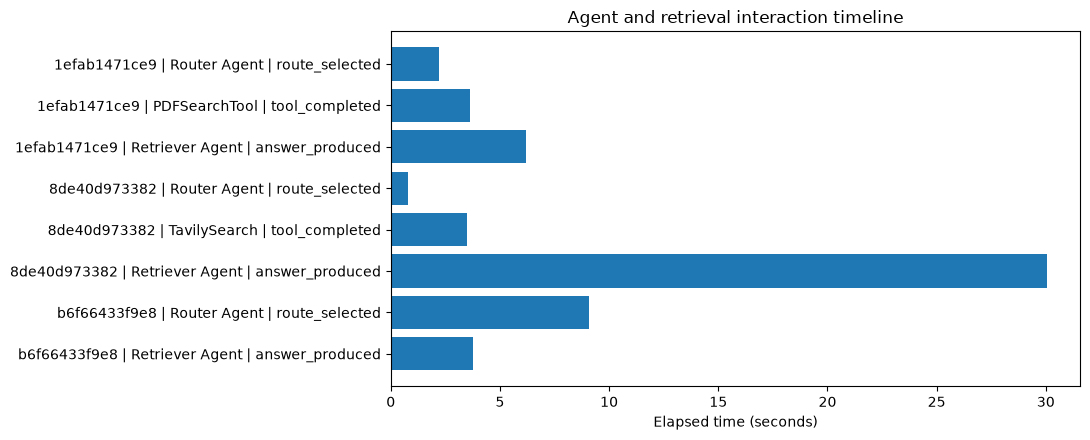

In [10]:
# 11. Timing visualization: routes, retrieval steps and tool calls.
if TRACE_EVENTS:
    timings = pd.DataFrame([
        {'stage': f"{e['run_id']} | {e['actor']} | {e['action']}", 'seconds': float(e['elapsed_sec'])}
        for e in TRACE_EVENTS if 'elapsed_sec' in e
    ])
    if not timings.empty:
        fig, ax = plt.subplots(figsize=(11, max(3.5, 0.50 * len(timings))))
        ax.barh(timings['stage'], timings['seconds'])
        ax.set_xlabel('Elapsed time (seconds)')
        ax.set_title('Agent and retrieval interaction timeline')
        ax.invert_yaxis()
        plt.tight_layout()
        plt.show()
else:
    print('Run the live demo to draw the trace timeline.')

## 12. Validation checks and failure modes

This simple test checks if completed runs used the correct tool. Routing quality is *model-dependent*, so inspect the results rather than assuming every run routes correctly. If the retrieval tool did not execute, this notebook raises an exception instead of treating unsupported text as a successful RAG answer.

In [11]:
# Invariants based on actual recorded events (requires live demo).
def audit_runs(results, events):
    rows = []
    for result in results:
        run_id = result['run_id']
        called = [e['actor'] for e in events if e['run_id'] == run_id and e['action'] == 'tool_completed']
        expected = {'PDF': 'PDFSearchTool', 'WEB': 'TavilySearch', 'GENERAL': None}[result['route']]
        ok = (expected in called and len(set(called)) == 1) if expected else (not called)
        rows.append({'run_id': run_id, 'route': result['route'], 'successful_tools': ', '.join(called) or 'none', 'pass': ok})
    return pd.DataFrame(rows)

if DEMO_RESULTS:
    audit = audit_runs(DEMO_RESULTS, TRACE_EVENTS)
    display(audit)
    assert audit['pass'].all(), 'At least one routed run used an unexpected retrieval tool.'
else:
    print('No completed live runs to audit.')

,run_id,route,successful_tools,pass
0,1efab1471ce9,PDF,PDFSearchTool,True
1,8de40d973382,WEB,"TavilySearch, TavilySearch",True
2,b6f66433f9e8,GENERAL,none,True


In [12]:
# 13. Custom questions: uncomment and change to evaluate your own query.
# user_question = 'What BLEU score did Transformer (big) achieve for English-to-German translation?'
# result = await run_agentic_rag(user_question)
# print(result['route'], '-', result['route_reason'])
# display(Markdown(result['answer']))

## 14. Technical discussion and trade-offs

| Decision | Rationale | Limitation |
|---|---|---|
| CrewAI agents + sequential tasks | Clear role separation and task accountability | Conditional route requires a Python control-flow boundary between crews |
| ChromaDB via `PDFSearchTool` | Dense-vector similarity retrieval from the uploaded PDF | Approximate similarity may miss tables, equations, or page references |
| Local ONNX embeddings | ChromaDB's MiniLM model avoids external embedding calls and an OpenAI key | First use may download the model; local retrieval quality differs from hosted embedding models |
| `langchain_tavily.TavilySearch` | Maintained integration for live Tavily search with source URLs | Requires a Tavily API key |
| Mandatory tool call checks | Prevents answer generation from masquerading as grounded retrieval | A successful tool call alone does not prove every answer statement is supported |
| JSONL event trace | Easy inspection and repeatable run IDs | Contains questions and outputs; handle private/sensitive inputs carefully |
| GENERAL route | Avoids unnecessary web/PDF calls | No evidence grounding; only suitable for non-factual/lightweight questions |

**Further improvements:** page-aware PDF ingestion, hybrid BM25+dense retrieval, answer citation validation, reranking, relevance thresholds, human escalation, offline test doubles, cost monitoring, per-user authorization, and persistent index configuration.

**Submission checklist:** attach the notebook and `README.md`. Keep the supplied PDF alongside the notebook when re-running; optionally include requirements.txt. Run all cells on your own machine or Colab with credentials and network, verify both routes, and export the generated `agentic_rag_trace.jsonl` if your LMS requests trace evidence.